# Credit Approval: Prediksi Status Kredit Nasabah

Proyek ini berasal dari uji kompetensi BNSP Associate Data Scientist. Waktu pengerjaannya hanya beberapa jam, jadi notebook aslinya jalan tetapi urutannya berantakan dan ada langkah yang terlewat. Di versi ini alur dan modelnya tetap sama, hanya beberapa bagian yang dibetulkan.

| Bagian | Notebook ujian | Notebook ini |
|---|---|---|
| `nama_nasabah` | ikut di-encode dan terpilih sebagai fitur | dibuang karena hanya nomor identitas |
| Urutan pemrosesan | imputasi, capping, seleksi fitur, dan scaling dilakukan sebelum data dibagi | data dibagi lebih dulu, semua nilai pemrosesan dihitung dari data latih |
| Umur tidak masuk akal | hanya dipotong dengan aturan IQR | nilai di luar 17 sampai 80 tahun dianggap kosong lalu diisi |
| Pembagian data | acak | acak dengan proporsi kelas dijaga (stratified) |
| Uji tambahan | tidak ada | model dicoba tanpa kolom tunggakan dan `col` |

Target yang diprediksi adalah `status_kredit`, yaitu LANCAR atau MACET.

# 1. Pengumpulan Data

Dataset berisi 766 nasabah pinjaman dengan 16 kolom. Nama nasabah sudah dianonimkan menjadi x1, x2, dan seterusnya. File yang dipakai adalah versi "kotor" dari soal ujian, jadi pembersihan data menjadi bagian utama pekerjaannya.

Sumber data: https://drive.google.com/file/d/1qb4Ahmx8XbwkL7WolMzQbU45gsCuas1s/view?usp=sharing

In [1]:
%pip install -q mljar-supervised

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, auc,
                             classification_report, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from supervised.automl import AutoML

warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
os.makedirs("images", exist_ok=True)


def save_fig(nama):
    plt.savefig(f"images/{nama}.png", dpi=150, bbox_inches="tight")

In [3]:
df = pd.read_csv("creditapproval-data kotor.csv", sep=";")
df = df.rename(columns={"status kredit": "status_kredit"})
df.head()

,nama_nasabah,jenis_kelamin,umur,jml_pinjaman,jkw,jml_angsuran_per_bulan,type_pinjaman,jenis_pinjaman,bi_sektor_ekonomi,col,bi_golongan_debitur,bi_gol_penjamin,saldo_nominatif,tunggakan_pokok,tunggakan_bunga,status_kredit
0,x1,P,40.0,345000,1.0,345000,100,301,6000.0,1,874,875,345000,345000,0,MACET
1,x2,L,31.0,350000,7.0,55716,100,301,6000.0,1,874,875,390000,111428,0,MACET
2,x3,L,NaN,649926,6.0,108321,100,301,6000.0,1,874,875,649926,216642,0,MACET
3,x4,P,2.0,459168,NaN,38264,100,301,6000.0,1,874,875,459168,382640,0,MACET
4,x5,WANITA,34.0,3055499,8.0,"381937,41",100,301,6000.0,1,874,875,3055499,"1527749,48",0,MACET


# 2. Menelaah Data

Lima baris pertama sudah menunjukkan beberapa masalah. Angsuran per bulan memakai koma sebagai desimal (`381937,41`), jenis kelamin ditulis "P" di satu baris dan "WANITA" di baris lain, ada sel `umur` dan `jkw` yang kosong, dan umur nasabah x4 tercatat 2 tahun.

In [4]:
pd.DataFrame({"tipe": df.dtypes, "kosong": df.isnull().sum()})

,tipe,kosong
nama_nasabah,object,0
jenis_kelamin,object,0
umur,float64,9
jml_pinjaman,object,0
jkw,float64,8
jml_angsuran_per_bulan,object,0
type_pinjaman,int64,0
jenis_pinjaman,int64,0
bi_sektor_ekonomi,float64,1
col,int64,0


In [5]:
print(df["jenis_kelamin"].unique())
print(df["status_kredit"].value_counts())

['P' 'L' 'WANITA' 'LAKI-LAKI' 'PRIA' 'PEREMPUAN']
status_kredit
MACET     556
LANCAR    210
Name: count, dtype: int64


Kolom `jml_pinjaman`, `jml_angsuran_per_bulan`, `saldo_nominatif`, dan kedua kolom tunggakan terbaca sebagai teks karena desimal koma, jadi harus diubah menjadi angka dulu. Nilai kosong ada di `umur` (9 baris), `jkw` (8 baris), dan `bi_sektor_ekonomi` (1 baris). Kategori jenis kelamin hanya dua, tetapi ditulis dengan enam variasi.

Kelas target tidak seimbang. Ada 556 nasabah MACET (72,6%) dan 210 LANCAR (27,4%). Model yang selalu menjawab MACET sudah benar di sekitar 73% data, jadi angka itu yang harus dilampaui.

# 3. Validasi dan Pembersihan Awal

Langkah di bagian ini berlaku per baris dan tidak belajar apa pun dari distribusi data, jadi aman dilakukan sebelum data dibagi. Perhitungan yang bergantung pada distribusi (median, batas outlier, skala) baru dikerjakan setelah pembagian.

In [6]:
kolom_koma = ["jml_pinjaman", "jml_angsuran_per_bulan", "saldo_nominatif",
              "tunggakan_pokok", "tunggakan_bunga"]

# format angka Indonesia: titik pemisah ribuan, koma pemisah desimal
for col in kolom_koma:
    df[col] = (df[col].astype(str)
                      .str.replace(".", "", regex=False)
                      .str.replace(",", ".", regex=False)
                      .astype(float))

peta_gender = {"L": 0, "LAKI-LAKI": 0, "LAKI LAKI": 0, "PRIA": 0,
               "P": 1, "PEREMPUAN": 1, "WANITA": 1}
df["jenis_kelamin"] = df["jenis_kelamin"].str.strip().str.upper().map(peta_gender)

# MACET = 1 supaya precision dan recall nanti dibaca untuk kelas bermasalah
df["status_kredit"] = (df["status_kredit"] == "MACET").astype(int)

# nama_nasabah hanya ID, type_pinjaman bernilai 100 di semua baris
df = df.drop(columns=["nama_nasabah", "type_pinjaman"])

df["jenis_kelamin"].value_counts(dropna=False)

jenis_kelamin
1    461
0    305
Name: count, dtype: int64

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
jenis_kelamin,766.0,6.018277e-01,4.898412e-01,0.00,0.0000,1.000,1.000000e+00,1.000000e+00
umur,757.0,2.907398e+01,2.645522e+02,-7162.00,32.0000,38.000,4.300000e+01,1.043000e+03
jml_pinjaman,766.0,2.712483e+06,9.995602e+06,83333.33,848928.5800,1500000.000,2.000000e+06,2.286550e+08
jkw,758.0,1.901187e+01,3.223143e+01,1.00,8.0000,12.000,2.000000e+01,6.790000e+02
jml_angsuran_per_bulan,766.0,2.333917e+05,5.489682e+05,0.00,67500.0000,105000.000,2.333334e+05,1.035000e+07
jenis_pinjaman,766.0,3.011971e+02,8.222667e-01,301.00,301.0000,301.000,3.010000e+02,3.050000e+02
bi_sektor_ekonomi,765.0,6.013046e+03,2.161963e+02,6000.00,6000.0000,6000.000,6.000000e+03,9.990000e+03
col,766.0,1.216710e+00,4.122727e-01,1.00,1.0000,1.000,1.000000e+00,2.000000e+00
bi_golongan_debitur,766.0,8.739687e+02,1.460257e+00,834.00,874.0000,874.000,8.740000e+02,8.760000e+02
bi_gol_penjamin,766.0,2.813003e+02,4.080990e+02,0.00,0.0000,0.000,8.750000e+02,8.750000e+02


Umur nasabah berkisar dari -7.162 sampai 1.043 tahun, jelas salah input, padahal median hanya 38 dan separuh data berada di rentang 32 sampai 43 tahun. Kolom `jkw` (jangka waktu) juga punya nilai maksimum 679, sementara 75% datanya di bawah 20.

Umur di luar 17 sampai 80 tahun saya anggap tidak valid dan dikosongkan, nanti diisi dengan median data latih. Memotong nilai seperti -7.162 ke batas IQR akan menghasilkan umur yang tetap tidak nyata, seperti 15,5 tahun di notebook ujian.

In [8]:
umur_wajar = df["umur"].between(17, 80)
tidak_wajar = (df["umur"].notna() & ~umur_wajar).sum()
df.loc[~umur_wajar, "umur"] = np.nan

print(f"umur tidak wajar yang dikosongkan: {tidak_wajar} baris")
print(f"saldo_nominatif negatif: {(df['saldo_nominatif'] < 0).sum()} baris")

umur tidak wajar yang dikosongkan: 27 baris
saldo_nominatif negatif: 3 baris


# 4. Eksplorasi Visual

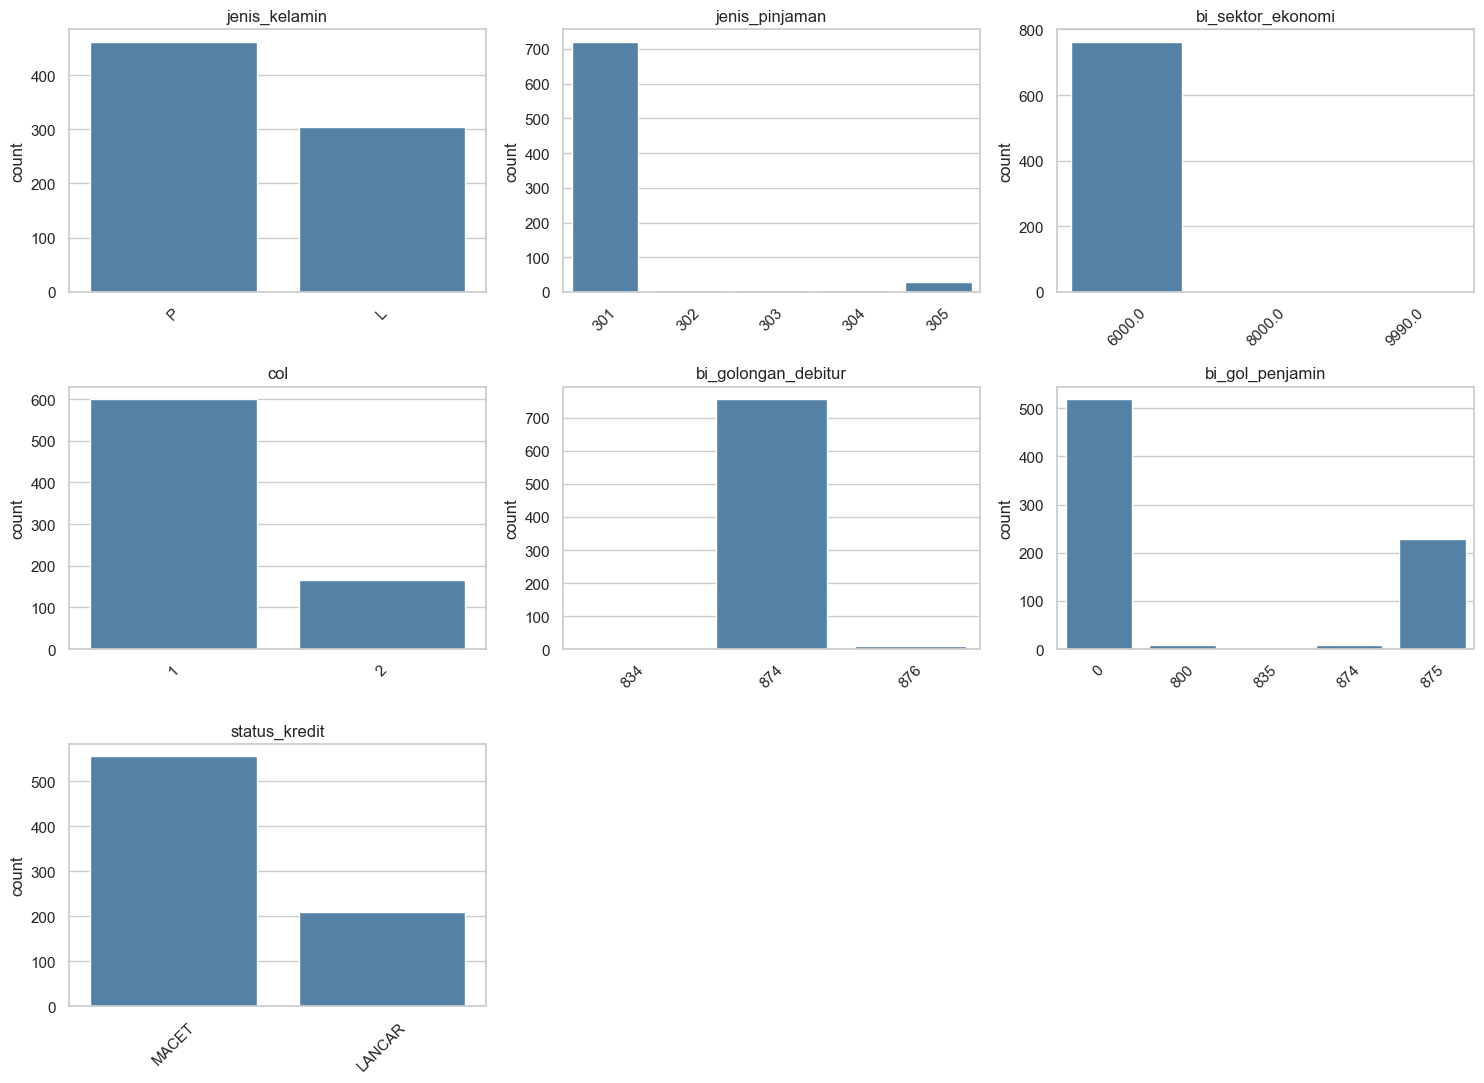

In [9]:
# kode numerik dikembalikan ke label hanya untuk grafik
df_plot = df.assign(
    jenis_kelamin=df["jenis_kelamin"].map({0: "L", 1: "P"}),
    status_kredit=df["status_kredit"].map({0: "LANCAR", 1: "MACET"}),
)
kolom_kategori = ["jenis_kelamin", "jenis_pinjaman", "bi_sektor_ekonomi", "col",
                  "bi_golongan_debitur", "bi_gol_penjamin", "status_kredit"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, kolom_kategori):
    sns.countplot(data=df_plot, x=col, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
for ax in axes.flat[len(kolom_kategori):]:
    ax.remove()

plt.tight_layout()
save_fig("01_distribusi_kategorikal")
plt.show()

Nasabah perempuan lebih banyak, sekitar 60% dari seluruh data. Hampir semua pinjaman berjenis 301, dan hampir semua debitur berada di golongan 874 dengan sektor ekonomi 6000. Karena nyaris tidak bervariasi, ketiga kolom ini hampir tidak membawa informasi untuk membedakan nasabah.

Kolom `col` terbagi menjadi sekitar 600 baris bernilai 1 dan sekitar 170 baris bernilai 2. Pada `bi_gol_penjamin`, sebagian besar nasabah bernilai 0 dan sisanya hampir semua bernilai 875.

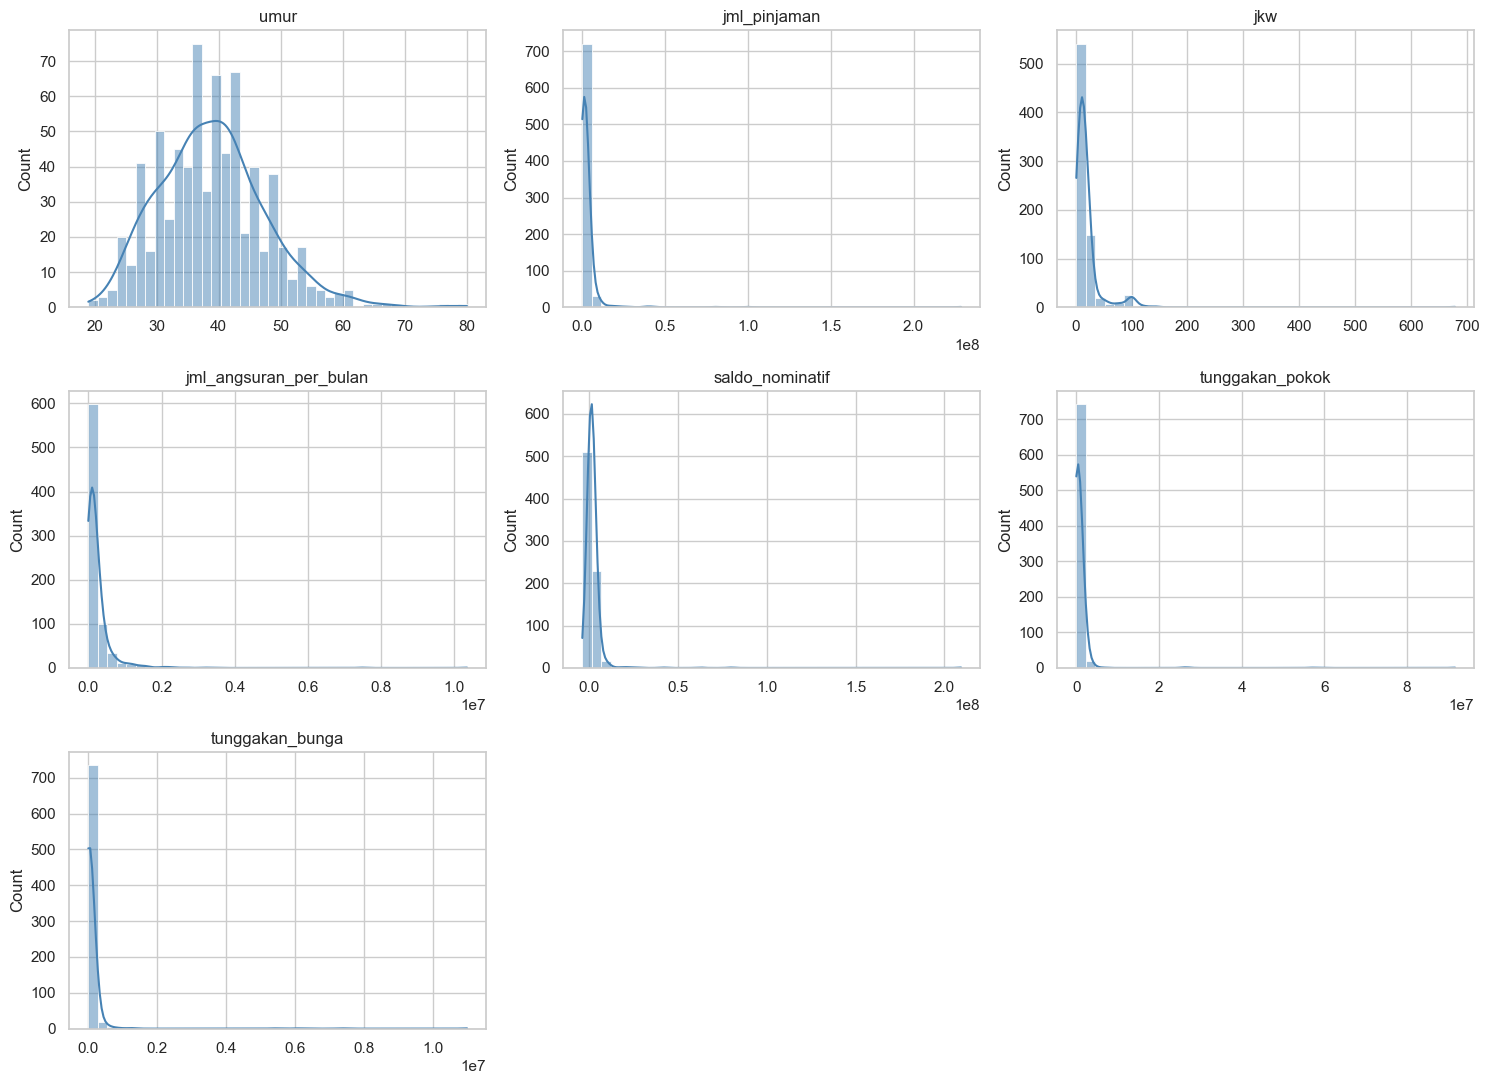

In [10]:
kolom_numerik = ["umur", "jml_pinjaman", "jkw", "jml_angsuran_per_bulan",
                 "saldo_nominatif", "tunggakan_pokok", "tunggakan_bunga"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, kolom_numerik):
    sns.histplot(df[col].dropna(), bins=40, kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.flat[len(kolom_numerik):]:
    ax.remove()

plt.tight_layout()
save_fig("02_distribusi_numerik")
plt.show()

In [ ]:
(df["tunggakan_bunga"] == 0).mean()

np.float64(0.5261096605744126)

In [27]:
(df["tunggakan_pokok"] == 0).mean()

np.float64(0.1866840731070496)

Hampir semua variabel uang miring ke kanan, dengan banyak nasabah di nilai kecil dan sedikit yang sangat besar. Lebih dari separuh nasabah tidak punya tunggakan bunga (nilainya nol), dan tunggakan pokok juga menumpuk di nol. Jangka waktu (`jkw`) mengumpul di bawah 20, dengan satu kelompok kecil di sekitar 100.

# 5. Pembagian Data

Pembagian dilakukan sebelum langkah pemrosesan apa pun yang menghitung statistik dari data. Dengan stratifikasi, proporsi MACET dan LANCAR di data latih dan data uji tetap sama.

In [11]:
X = df.drop(columns="status_kredit")
y = df["status_kredit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(X_train.shape, X_test.shape)

(612, 13) (154, 13)


# 6. Pemrosesan dari Data Latih

Semua nilai yang dipakai di sini (median, batas outlier, daftar fitur, rata-rata dan simpangan baku) dihitung dari data latih saja, lalu diterapkan apa adanya ke data uji.

## Nilai kosong

Kolom angka kontinu diisi median, sedangkan kolom kode (jenis kelamin, golongan, sektor) diisi modus karena rata-rata atau median dari sebuah kode tidak bermakna.

In [12]:
kolom_kode = [c for c in X_train.columns if c not in kolom_numerik]

isi = pd.concat([X_train[kolom_numerik].median(), X_train[kolom_kode].mode().iloc[0]])
X_train = X_train.fillna(isi)
X_test = X_test.fillna(isi)

## Outlier

Outlier tidak dibuang karena datanya hanya 766 baris. Nilai ekstrem dipotong ke batas IQR (Q1 - 1,5 x IQR dan Q3 + 1,5 x IQR) yang dihitung dari data latih.

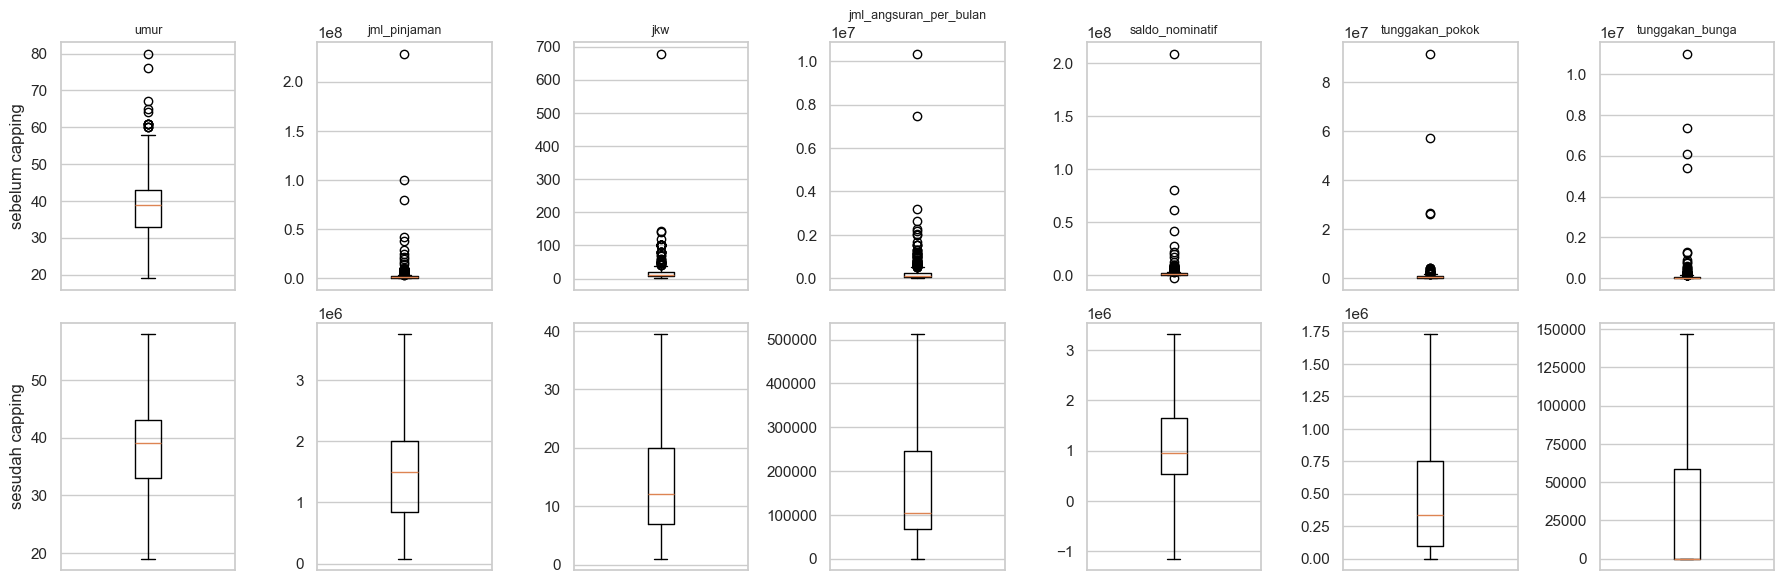

,jumlah_outlier
umur,13
jml_pinjaman,78
jkw,51
jml_angsuran_per_bulan,58
saldo_nominatif,59
tunggakan_pokok,38
tunggakan_bunga,60


In [13]:
q1 = X_train[kolom_numerik].quantile(0.25)
q3 = X_train[kolom_numerik].quantile(0.75)
batas_bawah = q1 - 1.5 * (q3 - q1)
batas_atas = q3 + 1.5 * (q3 - q1)

sebelum = X_train[kolom_numerik].copy()
jumlah_outlier = ((sebelum < batas_bawah) | (sebelum > batas_atas)).sum()

X_train[kolom_numerik] = X_train[kolom_numerik].clip(batas_bawah, batas_atas, axis=1)
X_test[kolom_numerik] = X_test[kolom_numerik].clip(batas_bawah, batas_atas, axis=1)

fig, axes = plt.subplots(2, len(kolom_numerik), figsize=(18, 6))
for i, col in enumerate(kolom_numerik):
    axes[0, i].boxplot(sebelum[col])
    axes[1, i].boxplot(X_train[col])
    axes[0, i].set_title(col, fontsize=9)
    axes[0, i].set_xticks([])
    axes[1, i].set_xticks([])
axes[0, 0].set_ylabel("sebelum capping")
axes[1, 0].set_ylabel("sesudah capping")

plt.tight_layout()
save_fig("03_boxplot_capping")
plt.show()

jumlah_outlier.rename("jumlah_outlier").to_frame()

Jumlah outlier berkisar dari sekitar 13 baris (`umur`) sampai 78 baris (`jml_pinjaman`) per kolom. Batas bawah `saldo_nominatif` bernilai negatif dan tercapai oleh datanya, artinya ada saldo negatif yang ekstrem. Nilainya tetap dipertahankan sebagai batas bawah karena belum bisa dipastikan salah input; bisa saja itu kelebihan bayar.

## Seleksi fitur

Fitur dipilih dari korelasi dengan target, dengan ambang 0,1 (nilai absolut), dihitung hanya dari data latih.

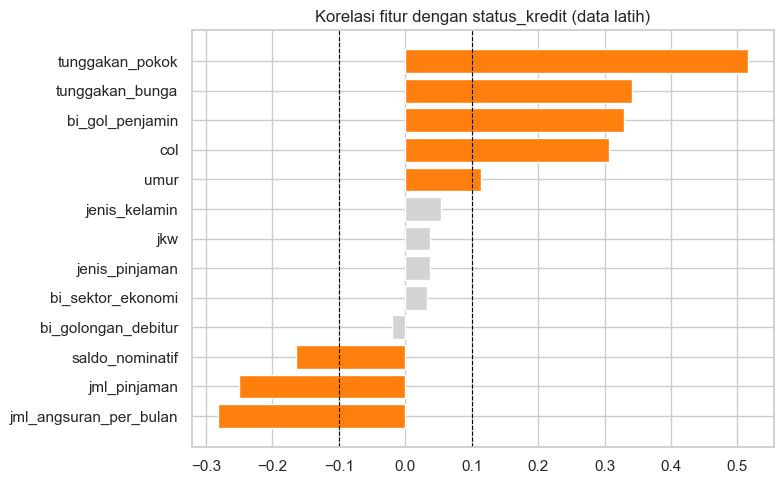

,korelasi
tunggakan_pokok,0.515
tunggakan_bunga,0.341
bi_gol_penjamin,0.330
col,0.307
umur,0.114
jenis_kelamin,0.054
jenis_pinjaman,0.038
jkw,0.038
bi_sektor_ekonomi,0.033
bi_golongan_debitur,-0.019


In [14]:
korelasi = X_train.corrwith(y_train).sort_values()
terpilih = korelasi[korelasi.abs() >= 0.1].index.tolist()

plt.figure(figsize=(8, 5))
warna = ["tab:orange" if abs(v) >= 0.1 else "lightgray" for v in korelasi]
plt.barh(korelasi.index, korelasi.values, color=warna)
plt.axvline(0.1, color="black", linestyle="--", linewidth=0.8)
plt.axvline(-0.1, color="black", linestyle="--", linewidth=0.8)
plt.title("Korelasi fitur dengan status_kredit (data latih)")

plt.tight_layout()
save_fig("04_korelasi_target")
plt.show()

korelasi.round(3).sort_values(ascending=False).to_frame("korelasi")

Pada notebook ujian, tunggakan pokok punya korelasi paling kuat dengan status MACET (0,515). Berikutnya `tunggakan_bunga`, `bi_gol_penjamin` , dan `col` dengan korelasi 0,33 sampai 0,34. Jumlah pinjaman dan angsuran per bulan berkorelasi negatif lemah (sekitar -0,25 dan -0,28): pinjaman yang lebih kecil sedikit lebih sering macet. Arahnya masuk akal, nasabah dengan tunggakan besar memang cenderung berstatus macet.

Sebelum model dilatih, fitur terpilih distandarkan dengan Z-score. Skala ini tidak berpengaruh pada model berbasis pohon, tetapi dibutuhkan oleh model linear, KNN, dan neural network yang ikut dicoba AutoML.

In [15]:
scaler = StandardScaler().fit(X_train[terpilih])

X_train_s = pd.DataFrame(scaler.transform(X_train[terpilih]),
                         columns=terpilih, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test[terpilih]),
                        columns=terpilih, index=X_test.index)

# 7. Membangun Model

Model dilatih dengan mljar-supervised dalam mode Explain, batas waktu 300 detik, dan akurasi sebagai metrik. Sepuluh algoritma dicoba, termasuk baseline yang selalu menebak kelas mayoritas. mljar membagi data latih lagi menjadi 75% untuk melatih dan 25% untuk validasi, jadi angka di leaderboard adalah akurasi validasi, bukan akurasi data uji.

In [16]:
# hapus folder automl_results kalau data atau fitur berubah, kalau tidak mljar memuat hasil lama
automl = AutoML(
    mode="Explain",
    total_time_limit=300,
    eval_metric="accuracy",
    algorithms=["Baseline", "CatBoost", "Decision Tree", "Extra Trees",
                "Nearest Neighbors", "LightGBM", "Linear", "Neural Network",
                "Random Forest", "Xgboost"],
    results_path="automl_results",
    random_state=RANDOM_STATE,
)
automl.fit(X_train_s, y_train)

AutoML directory: automl_results
The task is binary_classification with evaluation metric accuracy
AutoML will use algorithms: ['Baseline', 'CatBoost', 'Decision Tree', 'Extra Trees', 'Nearest Neighbors', 'LightGBM', 'Linear', 'Neural Network', 'Random Forest', 'Xgboost']
AutoML is generating and selecting models automatically. Review outputs before important use.
AutoML will ensemble available models
AutoML steps: ['simple_algorithms', 'default_algorithms', 'ensemble']
* Step simple_algorithms will try to check up to 3 models
1_Baseline accuracy 0.72549 trained in 0.69 seconds
2_DecisionTree accuracy 0.954248 trained in 14.19 seconds
3_Linear accuracy 0.960784 trained in 20.1 seconds
* Step default_algorithms will try to check up to 7 models
There was an error during 4_Default_LightGBM training.
Please check automl_results\errors.md for details.
5_Default_Xgboost accuracy 0.96732 trained in 15.9 seconds
6_Default_CatBoost accuracy 0.986928 trained in 5.05 seconds
7_Default_NeuralNetwo

,results_path,'automl_results'
,total_time_limit,300
,mode,'Explain'
,ml_task,'auto'
,model_time_limit,None
,algorithms,"['Baseline', 'CatBoost', ...]"
,train_ensemble,True
,stack_models,'auto'
,eval_metric,'accuracy'
,validation_strategy,'auto'
,explain_level,'auto'


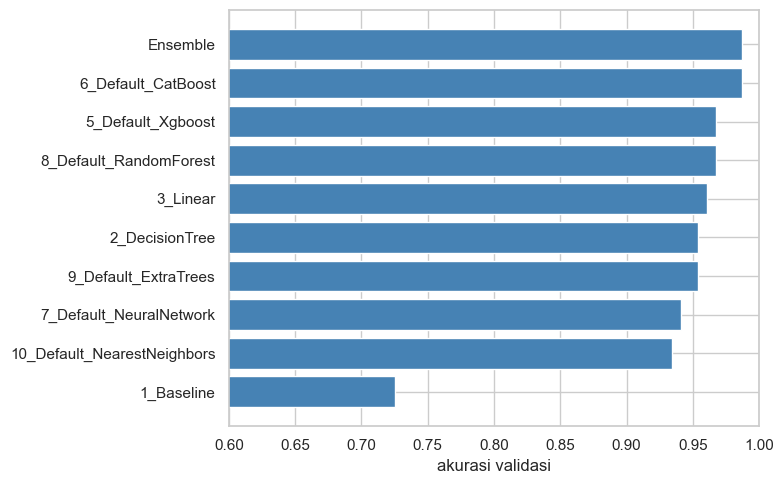

,name,model_type,akurasi_validasi,train_time
0,1_Baseline,Baseline,0.725490,2.11
1,2_DecisionTree,Decision Tree,0.954248,15.98
2,3_Linear,Linear,0.960784,22.16
3,5_Default_Xgboost,Xgboost,0.967320,18.28
4,6_Default_CatBoost,CatBoost,0.986928,7.19
5,7_Default_NeuralNetwork,Neural Network,0.941176,7.05
6,8_Default_RandomForest,Random Forest,0.967320,14.69
7,9_Default_ExtraTrees,Extra Trees,0.954248,8.13
8,10_Default_NearestNeighbors,Nearest Neighbors,0.934641,4.92
9,Ensemble,Ensemble,0.986928,2.81


In [17]:
leaderboard = automl.get_leaderboard()
# mljar menyimpan akurasi sebagai nilai negatif karena metriknya diminimalkan
leaderboard["akurasi_validasi"] = leaderboard["metric_value"].abs()
urut = leaderboard.sort_values("akurasi_validasi")

plt.figure(figsize=(8, 5))
plt.barh(urut["name"], urut["akurasi_validasi"], color="steelblue")
plt.xlim(0.6, 1)
plt.xlabel("akurasi validasi")

plt.tight_layout()
save_fig("05_leaderboard")
plt.show()

leaderboard[["name", "model_type", "akurasi_validasi", "train_time"]]

Baseline mendapat akurasi sekitar 0,73, hampir sama dengan proporsi kelas MACET, sesuai dugaan. Model lain berada di 0,93 sampai 0,99, dengan Nearest Neighbors paling rendah. CatBoost dan Ensemble sama-sama terbaik di 0,987, dan mljar memilih CatBoost sebagai model akhir. Selisihnya dengan XGBoost dan Random Forest (0,967) hanya sekitar tiga prediksi dari 153 data validasi, jadi urutan model teratas sebaiknya tidak dibaca terlalu kaku.

# 8. Evaluasi Model

Evaluasi memakai data uji yang tidak dipakai selama pemrosesan maupun pelatihan.

In [18]:
def hitung_metrik(X_, y_):
    pred = automl.predict(X_)
    proba = automl.predict_proba(X_)[:, 1]
    return {
        "accuracy": accuracy_score(y_, pred),
        "precision": precision_score(y_, pred),
        "recall": recall_score(y_, pred),
        "f1": f1_score(y_, pred),
        "auc": roc_auc_score(y_, proba),
    }


metrik = pd.DataFrame({"latih": hitung_metrik(X_train_s, y_train),
                       "uji": hitung_metrik(X_test_s, y_test)})
metrik["selisih"] = metrik["latih"] - metrik["uji"]
metrik.round(4)

,latih,uji,selisih
accuracy,0.9869,0.9740,0.0129
precision,0.9866,0.9821,0.0045
recall,0.9955,0.9821,0.0134
f1,0.9910,0.9821,0.0089
auc,0.9953,0.9879,0.0074


In [19]:
pred_uji = automl.predict(X_test_s)
print(classification_report(y_test, pred_uji, target_names=["LANCAR", "MACET"]))

              precision    recall  f1-score   support

      LANCAR       0.95      0.95      0.95        42
       MACET       0.98      0.98      0.98       112

    accuracy                           0.97       154
   macro avg       0.97      0.97      0.97       154
weighted avg       0.97      0.97      0.97       154



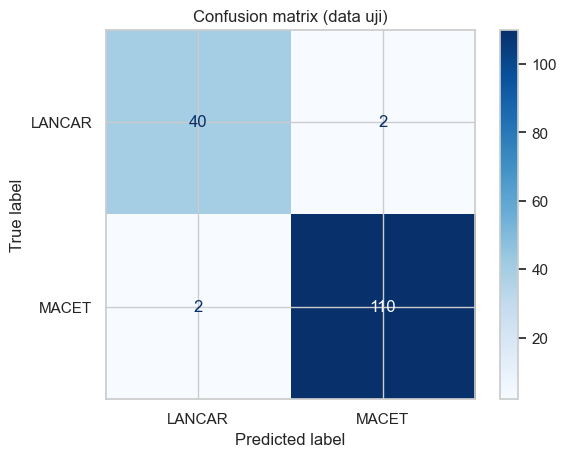

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_uji, display_labels=["LANCAR", "MACET"], cmap="Blues")
plt.title("Confusion matrix (data uji)")

save_fig("06_confusion_matrix")
plt.show()

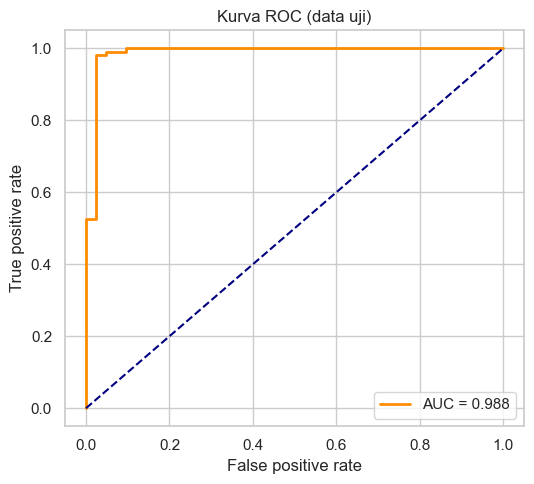

In [21]:
fpr, tpr, _ = roc_curve(y_test, automl.predict_proba(X_test_s)[:, 1])

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"AUC = {auc(fpr, tpr):.3f}")
plt.plot([0, 1], [0, 1], color="navy", linestyle="--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Kurva ROC (data uji)")
plt.legend(loc="lower right")

plt.tight_layout()
save_fig("07_roc_curve")
plt.show()

Pada data uji, model (CatBoost, pilihan otomatis mljar) mencapai akurasi 0,974, F1 0,982 untuk kelas MACET, dan AUC 0,988. Dari 154 nasabah, 4 salah diprediksi, masing-masing 2 untuk tiap kelas. Kelas LANCAR yang lebih sedikit tetap terdeteksi baik, dengan precision dan recall 0,95. Akurasi latih 0,987, selisihnya dengan data uji sekitar 0,01, jadi overfitting tidak terlalu parah. Karena data uji hanya 154 baris, satu kesalahan menggeser akurasi sekitar 0,65 poin persen, sehingga angka ini lebih tepat dibaca sebagai kisaran.

# 9. Uji Tambahan: Tanpa Kolom Tunggakan

Tunggakan pokok, tunggakan bunga, dan `col` adalah fitur dengan korelasi terkuat, dan secara bisnis ketiganya sudah menggambarkan kondisi kredit yang bermasalah. Untuk melihat seberapa jauh model bergantung pada kolom itu, tiga skenario dicoba dengan Random Forest sebagai model pembanding yang cepat.

In [22]:
def skor_rf(kolom):
    rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)
    rf.fit(X_train_s[kolom], y_train)
    return {
        "jumlah_fitur": len(kolom),
        "akurasi_uji": rf.score(X_test_s[kolom], y_test),
        "auc_uji": roc_auc_score(y_test, rf.predict_proba(X_test_s[kolom])[:, 1]),
    }


tanpa_col = [c for c in terpilih if c != "col"]
tanpa_semua = [c for c in terpilih
               if c not in ("col", "tunggakan_pokok", "tunggakan_bunga")]

pd.DataFrame({"semua fitur terpilih": skor_rf(terpilih),
              "tanpa col": skor_rf(tanpa_col),
              "tanpa col dan tunggakan": skor_rf(tanpa_semua)}).T.round(4).astype({"jumlah_fitur": int})

,jumlah_fitur,akurasi_uji,auc_uji
semua fitur terpilih,8,0.9740,0.9921
tanpa col,7,0.9740,0.9948
tanpa col dan tunggakan,5,0.7662,0.8261


Membuang col tidak mengubah hasil (akurasi 0,974), jadi kolom itu tampaknya tidak membawa informasi di luar tunggakan. Membuang kedua kolom tunggakan menurunkan akurasi ke 0,766, hanya sekitar empat poin di atas menebak MACET untuk semua nasabah (0,727), dan AUC turun dari 0,992 ke 0,826. Kemampuan model hampir seluruhnya bersumber dari tunggakan.

# 10. Kesimpulan

Model berbasis pohon dan boosting memprediksi status kredit dengan akurasi sekitar 95% pada validasi dan sekitar 97% pada data uji, jauh di atas baseline 73%. Dari korelasi, sinyal terkuat datang dari tunggakan pokok, lalu tunggakan bunga, `col`, dan golongan penjamin.

Beberapa hal yang membatasi hasil ini. Datanya hanya 766 baris dari satu sumber dan hanya diuji dengan satu kali pembagian latih-uji. Tunggakan baru diketahui setelah pinjaman berjalan, sehingga model ini belum bisa dipakai untuk memutuskan persetujuan kredit baru. Penanganan umur tidak wajar dan saldo negatif juga masih berupa aturan sederhana, bukan hasil konfirmasi ke pemilik data.